In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

df_clean = pd.read_csv("../data/hotel_bookings_clean.csv", parse_dates=['arrival_date'])
os.makedirs("../images", exist_ok=True)
sns.set_theme(style="whitegrid")

order = ['0-7 days', '8-30 days', '31-90 days', '91-180 days', '181-365 days', '365+ days']
df_clean['lead_time_group'] = pd.Categorical(df_clean['lead_time_group'], categories=order, ordered=True)

print(df_clean.shape)

(118563, 39)


In [2]:
def plot_cancel_rate(column, title, filename, sort=True):
    rate = df_clean.groupby(column, observed=True)['is_canceled'].mean() * 100

    if sort:
        rate = rate.sort_values(ascending=False)

    plt.figure(figsize=(9, 5))
    ax = sns.barplot(x=rate.index.astype(str), y=rate.values, color="#4C72B0")
    ax.bar_label(ax.containers[0], fmt='%.1f%%')

    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel('')
    plt.ylabel('Cancellation Rate (%)')
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(f"../images/{filename}.png", dpi=150)
    plt.show()

    return rate.round(1)

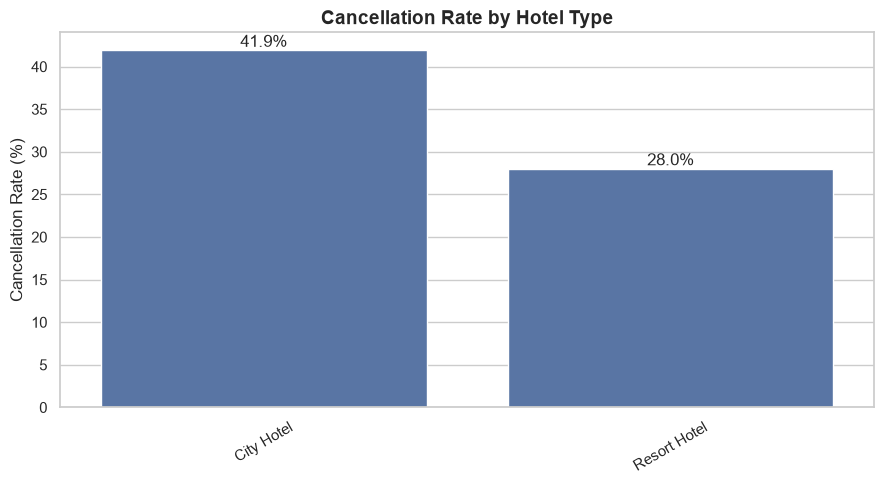

hotel
City Hotel      41.9
Resort Hotel    28.0
Name: is_canceled, dtype: float64

In [3]:
# Q1: City hotel versus tourist hotel
plot_cancel_rate('hotel', 'Cancellation Rate by Hotel Type', '01_hotel_type')

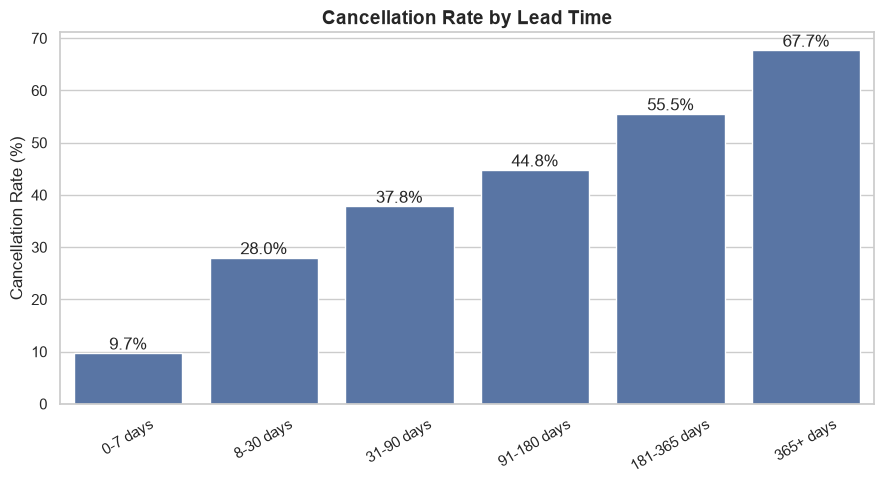

lead_time_group
0-7 days         9.7
8-30 days       28.0
31-90 days      37.8
91-180 days     44.8
181-365 days    55.5
365+ days       67.7
Name: is_canceled, dtype: float64

In [4]:
# Q2: Does early booking increase the likelihood of cancellation?
plot_cancel_rate('lead_time_group', 'Cancellation Rate by Lead Time', '02_lead_time', sort=False)

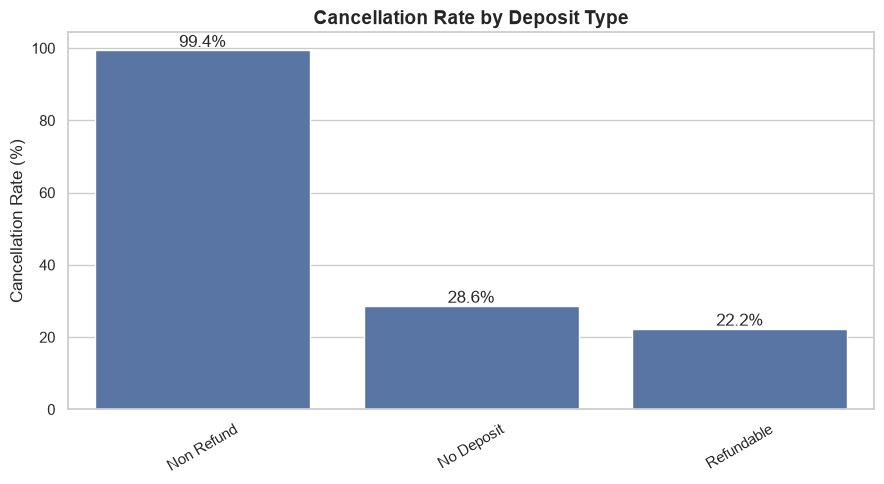

deposit_type
Non Refund    99.4
No Deposit    28.6
Refundable    22.2
Name: is_canceled, dtype: float64

In [5]:
# Q3: Does a deposit reduce cancellations?
plot_cancel_rate('deposit_type', 'Cancellation Rate by Deposit Type', '03_deposit_type')

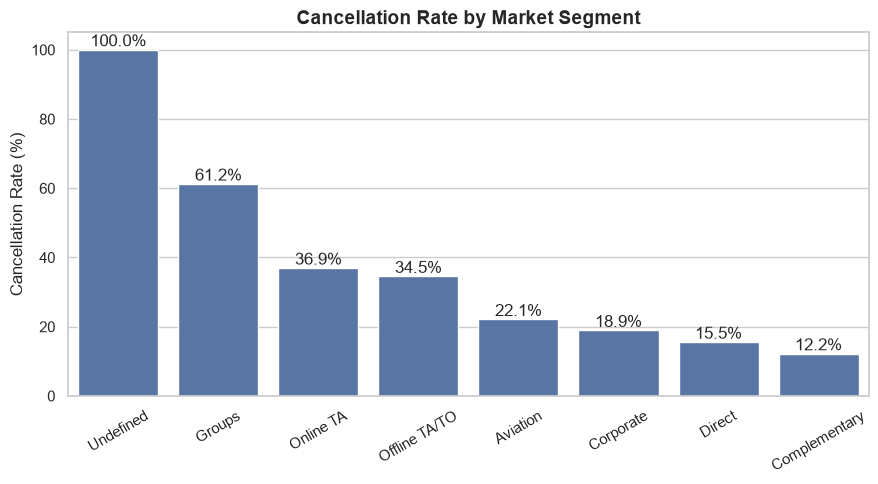

market_segment
Undefined        100.0
Groups            61.2
Online TA         36.9
Offline TA/TO     34.5
Aviation          22.1
Corporate         18.9
Direct            15.5
Complementary     12.2
Name: is_canceled, dtype: float64

In [6]:
# Q4: Which booking channels have the highest cancellation rates?
plot_cancel_rate('market_segment', 'Cancellation Rate by Market Segment', '04_market_segment')

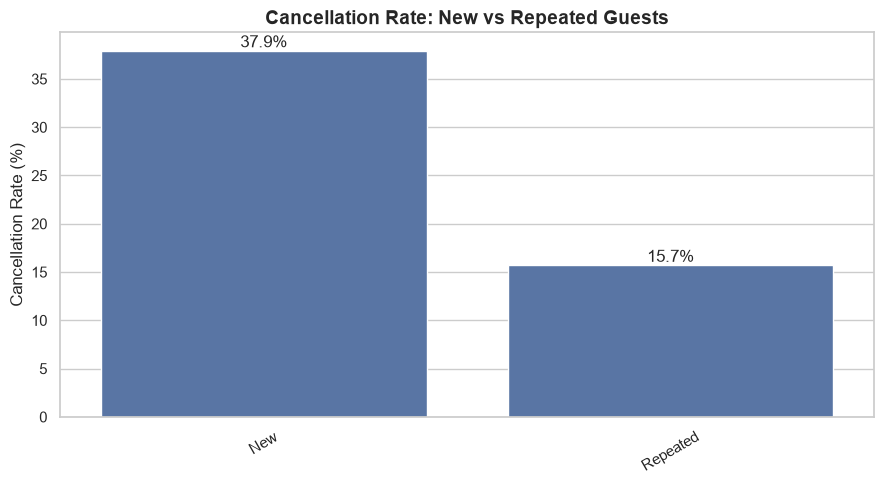

guest_type
New         37.9
Repeated    15.7
Name: is_canceled, dtype: float64

In [7]:
# Q5: New vs. Repeat Customers
df_clean['guest_type'] = np.where(df_clean['is_repeated_guest'] == 1, 'Repeated', 'New')
plot_cancel_rate('guest_type', 'Cancellation Rate: New vs Repeated Guests', '05_guest_type')

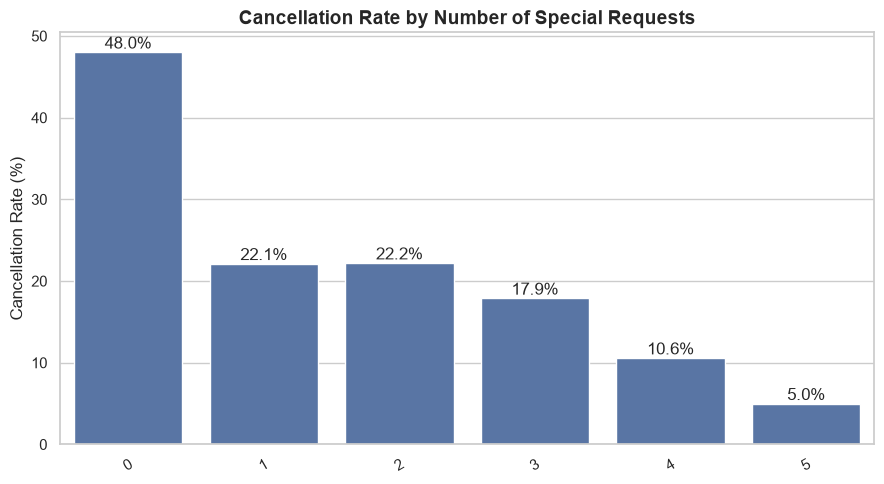

total_of_special_requests
0    48.0
1    22.1
2    22.2
3    17.9
4    10.6
5     5.0
Name: is_canceled, dtype: float64

In [8]:
# Q6: Are special requests affected by cancellation?
plot_cancel_rate('total_of_special_requests', 'Cancellation Rate by Number of Special Requests', '06_special_requests', sort=False)

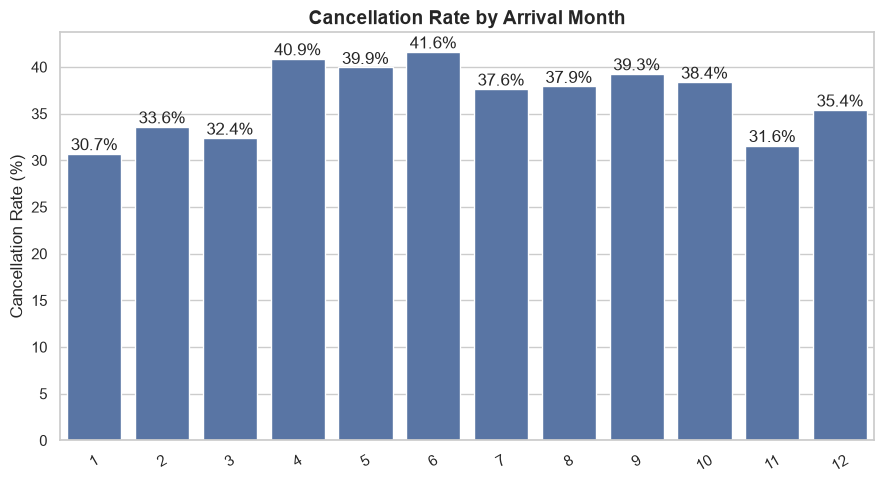

arrival_month_num
1     30.7
2     33.6
3     32.4
4     40.9
5     39.9
6     41.6
7     37.6
8     37.9
9     39.3
10    38.4
11    31.6
12    35.4
Name: is_canceled, dtype: float64

In [9]:
# Q7: Cancellation rate by month
plot_cancel_rate('arrival_month_num', 'Cancellation Rate by Arrival Month', '07_month', sort=False)

In [10]:
nr = df_clean[df_clean['deposit_type'] == 'Non Refund']

print("Number of non-refundable bookings:", len(nr))
print("\nDistributing it across booking channels (%):")
print(nr['market_segment'].value_counts(normalize=True).mul(100).round(1))
print("\nDistributing them to hotels (%):")
print(nr['hotel'].value_counts(normalize=True).mul(100).round(1))
print("\nPre-booking period terms: Non-refundable =", nr['lead_time'].median(), "| all =", df_clean['lead_time'].median())
print("Repeat customer rate: Non-refundable =", round(nr['is_repeated_guest'].mean()*100, 1), "% | all =", round(df_clean['is_repeated_guest'].mean()*100, 1), "%")

Number of non-refundable bookings: 14586

Distributing it across booking channels (%):
market_segment
Groups           62.9
Offline TA/TO    34.3
Corporate         2.3
Online TA         0.4
Direct            0.1
Name: proportion, dtype: float64

Distributing them to hotels (%):
hotel
City Hotel      88.2
Resort Hotel    11.8
Name: proportion, dtype: float64

Pre-booking period terms: Non-refundable = 183.0 | all = 70.0
Repeat customer rate: Non-refundable = 0.4 % | all = 3.0 %


## Key Insights

1. **Lead time is the strongest driver:** cancellation rises from 9.7% (≤7 days) to 67.7% (365+ days).
2. **City Hotel cancels more:** 41.9% vs 28.0% for Resort Hotel.
3. **Non-refundable deposits show 99.4% cancellation:** counter-intuitive, likely driven by group/agency block bookings. Correlation ≠ causation.
4. **Groups (61.2%) and Online TA (36.9%)** are the riskiest channels; Direct bookings cancel only 15.5%.
5. **Repeated guests cancel 2.4x less** than new guests (15.7% vs 37.9%).
6. **Special requests signal commitment:** 0 requests → 48% cancellation, 5 requests → 5%.
7. **Seasonality:** highest cancellation in April–June (~40–42%).

## Recommendations
- Require partial deposits for bookings made 90+ days in advance.
- Incentivize direct bookings (discounts, perks) to reduce reliance on high-cancellation channels.
- Launch a loyalty program to convert new guests into repeat guests.
- Flag bookings with no special requests and long lead times as high-risk for overbooking strategy.